In [ ]:
supervised learning algo-> classification(linear and non-linear)
used for regression prblm
used for outlier detection task

appln- sentimental analysis, image recognition and classification, handwriting identifications,spam detection, face cdetection anomaly det4ectin gene exprression analysis

svm linear: 2d surface, a straight line that classifies data points,
also called max margin linear classifier- setting max margin
ensures that margin b/w the closest points of diff classes(support vectors) is maximized 


svm non-linear: hyperplane
the dimension of the hyperplane depends on no:of features
there can be multiple planes or decision boundaries to segregate the classes in n-dimensional space- we need to find out the best decision boundary that helps to classify the data points. this best boundary is the hyperplane.

simply svm is a machine learning algo to find hyperplane in n-dimensional space that distincly classify the data points. (n-> no:of margins)

when outliers are there need to miss-classify or ignore it.
if we consider outliers- min margin- wrong prediction.

soft-margin formulation: it allows svm to make a certain number of mistakes and keep margin as wide as possible so that other data points can still be classified correctly to make corect classification.

how to perform miss-classification? -> with the help of a hyper-parameter: c-parameter-> it tells the svm how much to avoid miss-classifying in each training.
=>when c-parameter is increased-> min margin

Errors in svm:
    - classification error (A)
    - margin error (B)
    svm goal=min(cA+B)


In [5]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report
import matplotlib.pyplot as plt

In [12]:
X,y=make_classification(n_samples=1000,n_features=2,n_informative=2,n_redundant=0,random_state=42)
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [21]:
s=SVC(kernel='linear')
s.fit(X_train,y_train)
y_pred = s.predict(X_test)
ac=accuracy_score(y_test,y_pred)
print(ac)
report=classification_report(y_test,y_pred)
print(f"{report}")

0.88
              precision    recall  f1-score   support

           0       0.88      0.88      0.88       101
           1       0.88      0.88      0.88        99

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.88      0.88      0.88       200



plotting the decision boundary

C:\Users\HP\AppData\Local\Temp\ipykernel_16336\3191241433.py:2: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[:,0],X[:,1],cmap='viridis',s=50,alpha=0.6)


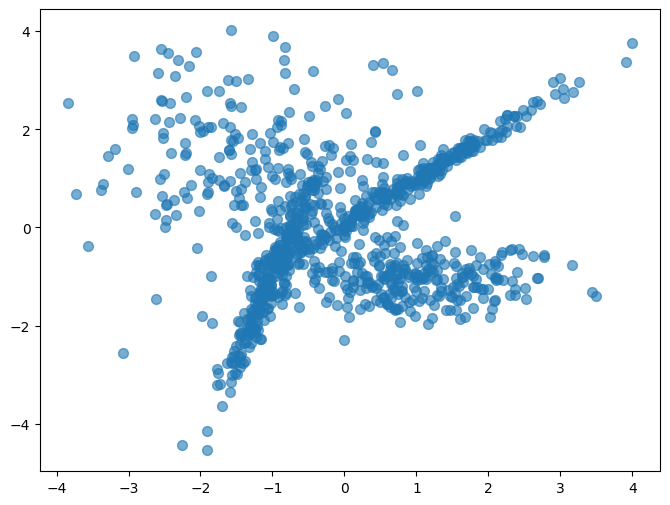

In [27]:
plt.figure(figsize=(8,6))
plt.scatter(X[:,0],X[:,1],cmap='viridis',s=50,alpha=0.6)

gca=> return current axis 

get_xlim=> x axis limit

get_ylim=>  y axis limit

meshgrid=> 

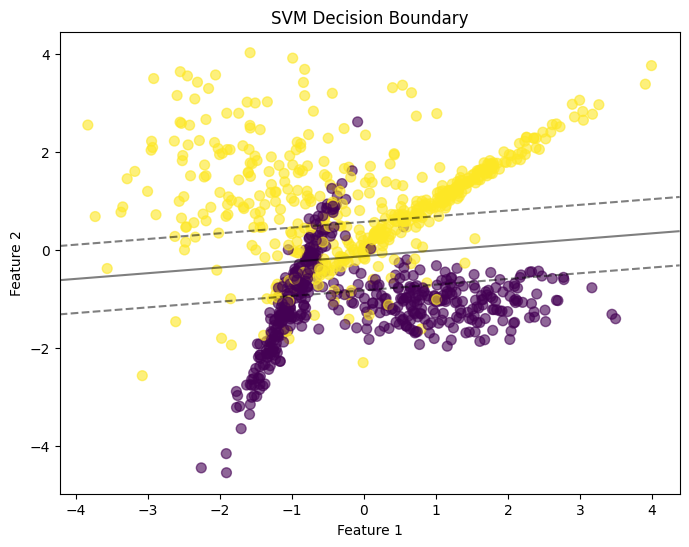

In [47]:
import numpy as np
plt.figure(figsize=(8,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='viridis',s=50,alpha=0.6)
ax=plt.gca()
xlimit=ax.set_xlim()
ylimit=ax.set_ylim()
xx,yy=np.meshgrid(np.linspace(xlimit[0],xlimit[1],100),np.linspace(ylimit[0],ylimit[1],100)) #linespace-> line between to space
z=s.decision_function(np.c_[xx.ravel(),yy.ravel()]) #ravel=> flaatens the 2-d array
z=z.reshape(xx.shape)
plt.contour(xx,yy,z,colors='k',levels=[-1,0,1],alpha=0.5,linestyles=['--','-','--'])#return no:of pos of region
plt.title("SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()